In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.parse import urlparse
import ipaddress
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

In [31]:
df = pd.read_csv("urldata.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (450176, 4)


,Unnamed: 0,url,label,result
0,0,https://www.google.com,benign,0
1,1,https://www.youtube.com,benign,0
2,2,https://www.facebook.com,benign,0
3,3,https://www.baidu.com,benign,0
4,4,https://www.wikipedia.org,benign,0


In [32]:
print("Columns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Columns:
Index(['Unnamed: 0', 'url', 'label', 'result'], dtype='object')

Data Types:
Unnamed: 0     int64
url           object
label         object
result         int64
dtype: object

Missing Values:
Unnamed: 0    0
url           0
label         0
result        0
dtype: int64

Duplicate Rows:
0


In [33]:
print(df["label"].value_counts())
print()
print(df["result"].value_counts())

label
benign       345738
malicious    104438
Name: count, dtype: int64

result
0    345738
1    104438
Name: count, dtype: int64


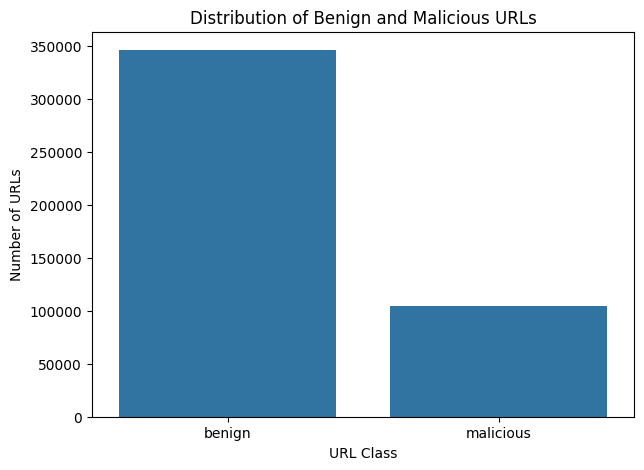

In [34]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Benign and Malicious URLs")
plt.xlabel("URL Class")
plt.ylabel("Number of URLs")

plt.show()

In [35]:
df = df.drop(columns=["Unnamed: 0"])

In [36]:
print(df.columns)

Index(['url', 'label', 'result'], dtype='object')


In [37]:
SUSPICIOUS_WORDS = re.compile(
    r"(login|signin|verify|verification|secure|account|update|"
    r"confirm|password|bank|payment|wallet|billing|authenticate)",
    re.IGNORECASE
)


def extract_features(url):

    url = str(url)


    try:
        parsed = urlparse(
            url if re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", url)
            else "//" + url
        )
    except:
        parsed = urlparse("//")

    hostname = parsed.hostname or ""
    path = parsed.path or ""
    query = parsed.query or ""


    try:
        ipaddress.ip_address(hostname)
        has_ip = 1
    except:
        has_ip = 0


    host_parts = [part for part in hostname.split(".") if part]

    if has_ip:
        subdomain_count = 0
    else:
        subdomain_count = max(0, len(host_parts) - 2)

    digit_count = sum(char.isdigit() for char in url)

    special_char_count = sum(
        not char.isalnum() for char in url
    )

    digit_ratio = (
        digit_count / len(url)
        if len(url) > 0
        else 0
    )


    return {
        "url_length": len(url),
        "hostname_length": len(hostname),
        "path_length": len(path),
        "query_length": len(query),

        "digit_count": digit_count,
        "digit_ratio": digit_ratio,

        "special_char_count": special_char_count,

        "dot_count": url.count("."),
        "slash_count": url.count("/"),
        "hyphen_count": url.count("-"),

        "at_count": url.count("@"),
        "question_count": url.count("?"),
        "ampersand_count": url.count("&"),
        "equals_count": url.count("="),
        "percent_count": url.count("%"),
        "underscore_count": url.count("_"),

        "subdomain_count": subdomain_count,

        "has_https": int(parsed.scheme.lower() == "https"),
        "has_ip": has_ip,
        "has_www": int(hostname.lower().startswith("www.")),

        "suspicious_keyword": int(
            bool(SUSPICIOUS_WORDS.search(url))
        )
    }

In [38]:
features = df["url"].apply(extract_features)

features = pd.DataFrame(features.tolist())

print("Feature Shape:", features.shape)

features.head()

Feature Shape: (450176, 21)


,url_length,hostname_length,path_length,query_length,digit_count,digit_ratio,special_char_count,dot_count,slash_count,hyphen_count,...,question_count,ampersand_count,equals_count,percent_count,underscore_count,subdomain_count,has_https,has_ip,has_www,suspicious_keyword
0,22,14,0,0,0,0.0,5,2,2,0,...,0,0,0,0,0,1,1,0,1,0
1,23,15,0,0,0,0.0,5,2,2,0,...,0,0,0,0,0,1,1,0,1,0
2,24,16,0,0,0,0.0,5,2,2,0,...,0,0,0,0,0,1,1,0,1,0
3,21,13,0,0,0,0.0,5,2,2,0,...,0,0,0,0,0,1,1,0,1,0
4,25,17,0,0,0,0.0,5,2,2,0,...,0,0,0,0,0,1,1,0,1,0


In [39]:
features.columns

Index(['url_length', 'hostname_length', 'path_length', 'query_length',
       'digit_count', 'digit_ratio', 'special_char_count', 'dot_count',
       'slash_count', 'hyphen_count', 'at_count', 'question_count',
       'ampersand_count', 'equals_count', 'percent_count', 'underscore_count',
       'subdomain_count', 'has_https', 'has_ip', 'has_www',
       'suspicious_keyword'],
      dtype='object')

In [40]:
data = pd.concat(
    [
        features,
        df[["result"]].reset_index(drop=True)
    ],
    axis=1
)

print(data.shape)
data.head()

(450176, 22)


,url_length,hostname_length,path_length,query_length,digit_count,digit_ratio,special_char_count,dot_count,slash_count,hyphen_count,...,ampersand_count,equals_count,percent_count,underscore_count,subdomain_count,has_https,has_ip,has_www,suspicious_keyword,result
0,22,14,0,0,0,0.0,5,2,2,0,...,0,0,0,0,1,1,0,1,0,0
1,23,15,0,0,0,0.0,5,2,2,0,...,0,0,0,0,1,1,0,1,0,0
2,24,16,0,0,0,0.0,5,2,2,0,...,0,0,0,0,1,1,0,1,0,0
3,21,13,0,0,0,0.0,5,2,2,0,...,0,0,0,0,1,1,0,1,0,0
4,25,17,0,0,0,0.0,5,2,2,0,...,0,0,0,0,1,1,0,1,0,0


EDA


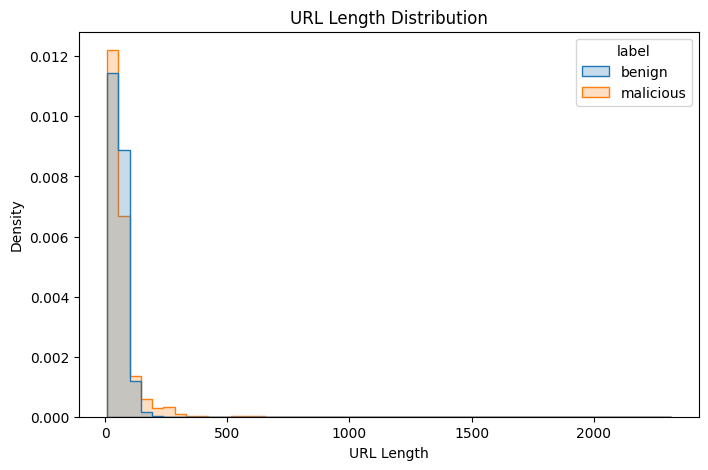

In [41]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="url_length",
    hue=df["label"],
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("URL Length Distribution")
plt.xlabel("URL Length")
plt.ylabel("Density")

plt.show()

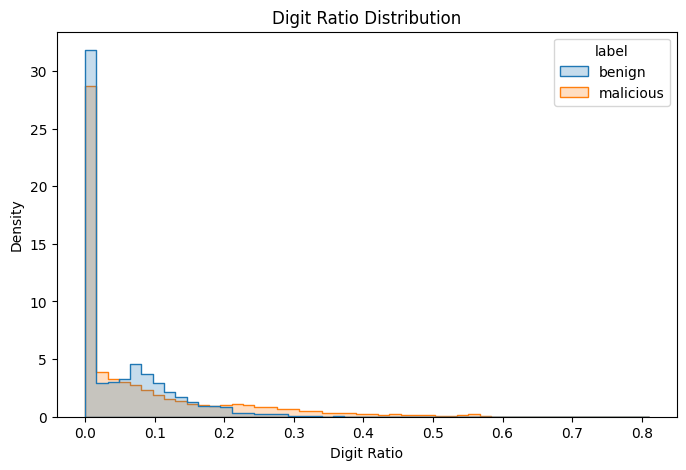

In [42]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="digit_ratio",
    hue=df["label"],
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Digit Ratio Distribution")
plt.xlabel("Digit Ratio")
plt.ylabel("Density")

plt.show()

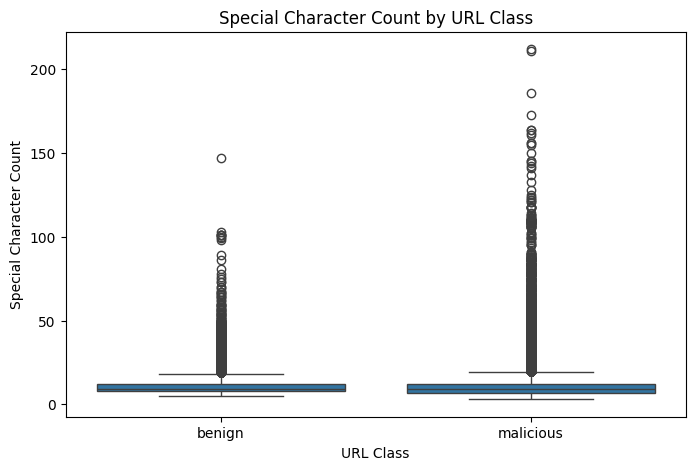

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x=df["label"],
    y="special_char_count"
)

plt.title("Special Character Count by URL Class")
plt.xlabel("URL Class")
plt.ylabel("Special Character Count")

plt.show()

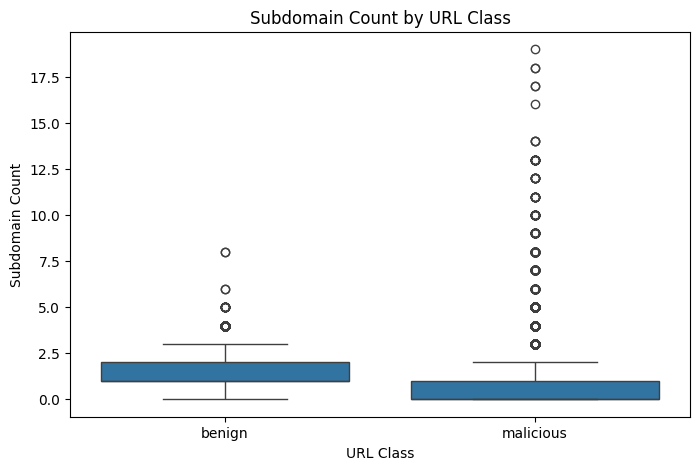

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x=df["label"],
    y="subdomain_count"
)

plt.title("Subdomain Count by URL Class")
plt.xlabel("URL Class")
plt.ylabel("Subdomain Count")

plt.show()

corr

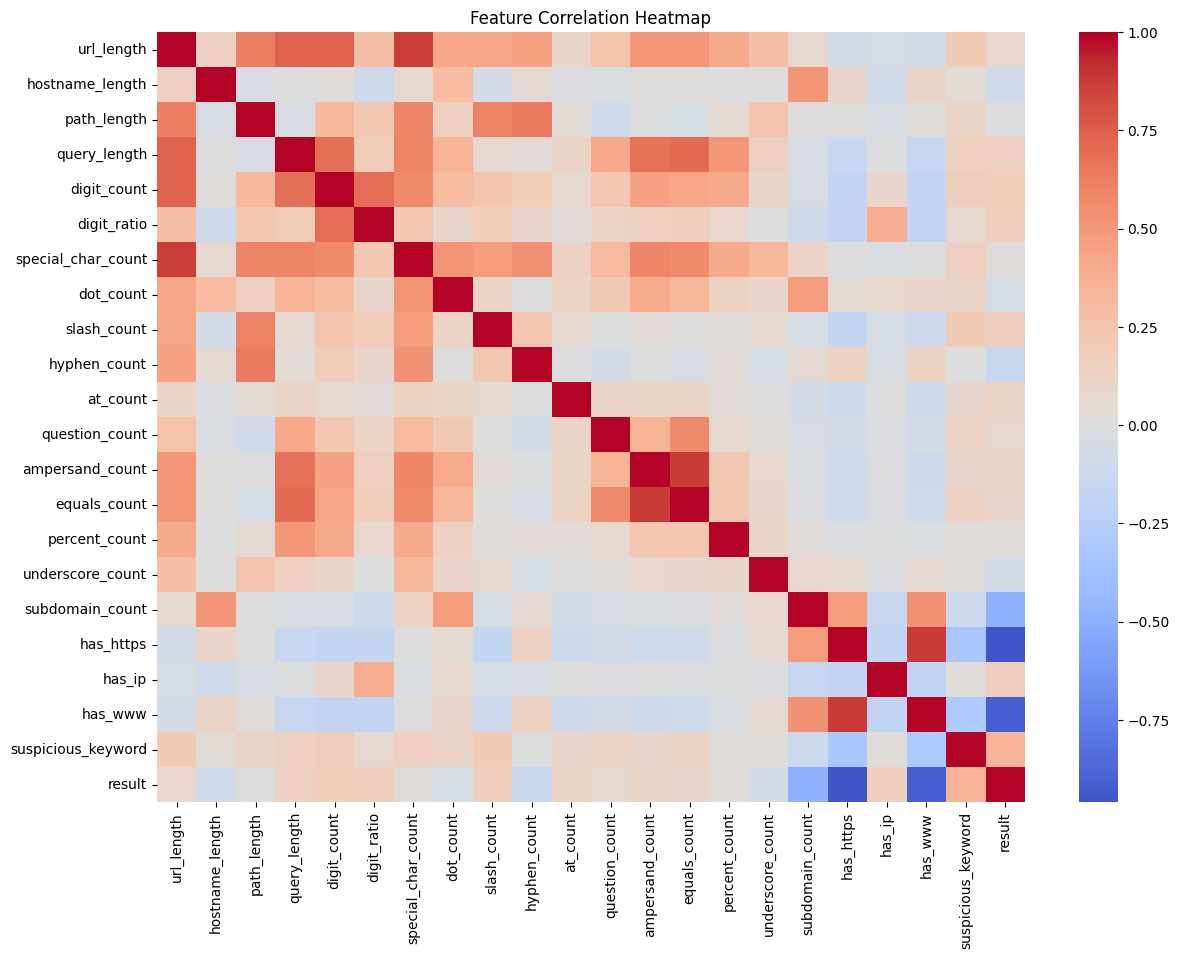

In [45]:
plt.figure(figsize=(14, 10))

correlation = data.corr(numeric_only=True)

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [46]:
class_summary = data.groupby(df["label"]).mean(numeric_only=True)

class_summary.T

label,benign,malicious
url_length,58.481443,66.052366
hostname_length,19.616311,18.152990
path_length,27.577379,26.968125
query_length,3.151438,13.434621
digit_count,3.275819,7.234158
digit_ratio,0.048155,0.080512
special_char_count,10.502051,10.666817
dot_count,2.652283,2.515512
slash_count,4.297908,4.927708
hyphen_count,1.461506,0.558140


In [47]:
X = data.drop(columns=["result"])
y = data["result"]

In [48]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (450176, 21)
y shape: (450176,)


split

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (360140, 21)
Test shape: (90036, 21)


In [50]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [51]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=10, random_state=42)

In [52]:
def evaluate_model(name, y_true, y_pred, y_proba):
    print(f"===== {name} =====")
    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall   :", recall_score(y_true, y_pred))
    print("F1 Score :", f1_score(y_true, y_pred))
    print("ROC-AUC  :", roc_auc_score(y_true, y_proba))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

In [53]:
log_pred = log_reg.predict(X_test_scaled)
log_proba = log_reg.predict_proba(X_test_scaled)[:, 1]
evaluate_model("Logistic Regression", y_test, log_pred, log_proba)

dt_pred = dt.predict(X_test)
dt_proba = dt.predict_proba(X_test)[:, 1]
evaluate_model("Decision Tree", y_test, dt_pred, dt_proba)

===== Logistic Regression =====
Accuracy : 0.9967235328090985
Precision: 0.9926790755538543
Recall   : 0.9932018383761011
F1 Score : 0.9929403881589968
ROC-AUC  : 0.9980641914953394

Confusion Matrix:
[[68995   153]
 [  142 20746]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     69148
           1       0.99      0.99      0.99     20888

    accuracy                           1.00     90036
   macro avg       1.00      1.00      1.00     90036
weighted avg       1.00      1.00      1.00     90036

===== Decision Tree =====
Accuracy : 0.9972122262206229
Precision: 0.9969657563935848
Recall   : 0.990999617004979
F1 Score : 0.9939737341240307
ROC-AUC  : 0.9968697178806432

Confusion Matrix:
[[69085    63]
 [  188 20700]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     69148
           1       1.00      0.99      0.99     20888

    

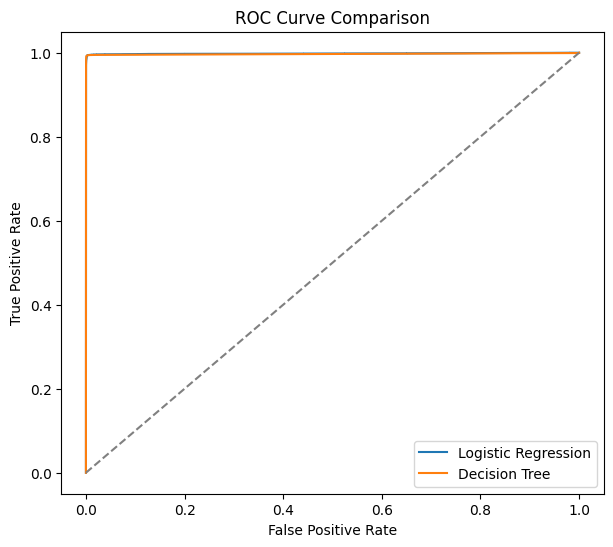

In [54]:
fpr_log, tpr_log, _ = roc_curve(y_test, log_proba)
fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr_log, tpr_log, label="Logistic Regression")
plt.plot(fpr_dt, tpr_dt, label="Decision Tree")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

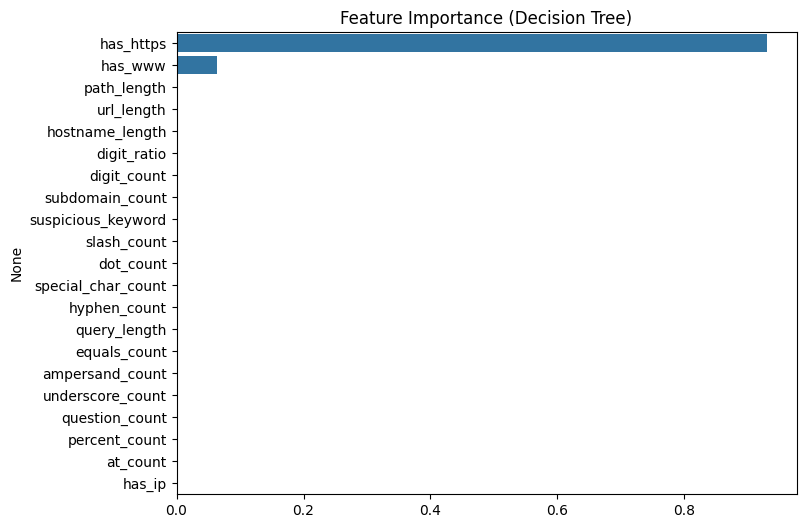

has_https             0.930063
has_www               0.063275
path_length           0.001792
url_length            0.001214
hostname_length       0.000704
digit_ratio           0.000451
digit_count           0.000429
subdomain_count       0.000365
suspicious_keyword    0.000325
slash_count           0.000291
dot_count             0.000223
special_char_count    0.000210
hyphen_count          0.000186
query_length          0.000121
equals_count          0.000101
ampersand_count       0.000095
underscore_count      0.000075
question_count        0.000040
percent_count         0.000022
at_count              0.000017
has_ip                0.000000
dtype: float64


In [55]:
importances = pd.Series(dt.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index)
plt.title("Feature Importance (Decision Tree)")
plt.show()

print(importances)

In [56]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(y_test, log_pred), accuracy_score(y_test, dt_pred)],
    "Precision": [precision_score(y_test, log_pred), precision_score(y_test, dt_pred)],
    "Recall": [recall_score(y_test, log_pred), recall_score(y_test, dt_pred)],
    "F1": [f1_score(y_test, log_pred), f1_score(y_test, dt_pred)],
    "ROC-AUC": [roc_auc_score(y_test, log_proba), roc_auc_score(y_test, dt_proba)],
})
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.996724,0.992679,0.993202,0.992940,0.998064
1,Decision Tree,0.997212,0.996966,0.991000,0.993974,0.996870


In [57]:
import joblib

final_model = log_reg
joblib.dump(final_model, "phishing_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']